# Locked temporal replication and operational warning

**Question:** Do the previously nominated UCL temporal signals survive locked chronological replication and yield useful warnings at a reasonable alert burden?

This notebook summarizes fixed-model results. Original training: 2015–2021; development: 2022–2023; 2024–2025 remains exploratory transfer. 2026 is retrospective locked replication, not prospective or fully independent confirmation. No model, feature, interval, regularization or threshold is chosen here.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
while not (ROOT / 'src/injury_analysis').exists():
    if ROOT == ROOT.parent: raise RuntimeError('Project root not found')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from IPython.display import display, Markdown, Image
from src.injury_analysis.ucl_replication_common import OUT, read, locked
spec = locked()
print('Frozen at:', spec['frozen_at_utc'])
print('Candidates:', ', '.join(spec['candidate_families']))
print('No predictive model refits; original files hash-verified.')
def show(name): display(Image(filename=str(OUT/'figures'/(name+'.png'))))

Frozen at: 2026-10-22T03:02:19.643904+00:00
Candidates: Velocity, Pitcher background and experience
No predictive model refits; original files hash-verified.


## Cohort support and censoring

All interval comparisons use the identical observed 60-day first-event risk set. Unknown late-season outcomes remain censored. Qualifying events without a prediction opportunity remain in the all-event warning denominator.

,interval,appearance_rows,eligible_landmarks,rows,unknown_rows,pitchers,positive_rows,prevalence,represented_events,qualifying_events,observable_events,latest_appearance,latest_observed_eventfree
0,1-7,20658,19934,11203,8731,546,29,0.002589,16,21,16,2026-09-27,2026-07-29
1,8-14,20658,19934,11203,8731,546,18,0.001607,11,21,11,2026-09-27,2026-07-29
2,15-30,20658,19934,11203,8731,546,36,0.003213,12,21,12,2026-09-27,2026-07-29
3,31-60,20658,19934,11203,8731,546,55,0.004909,9,21,9,2026-09-27,2026-07-29


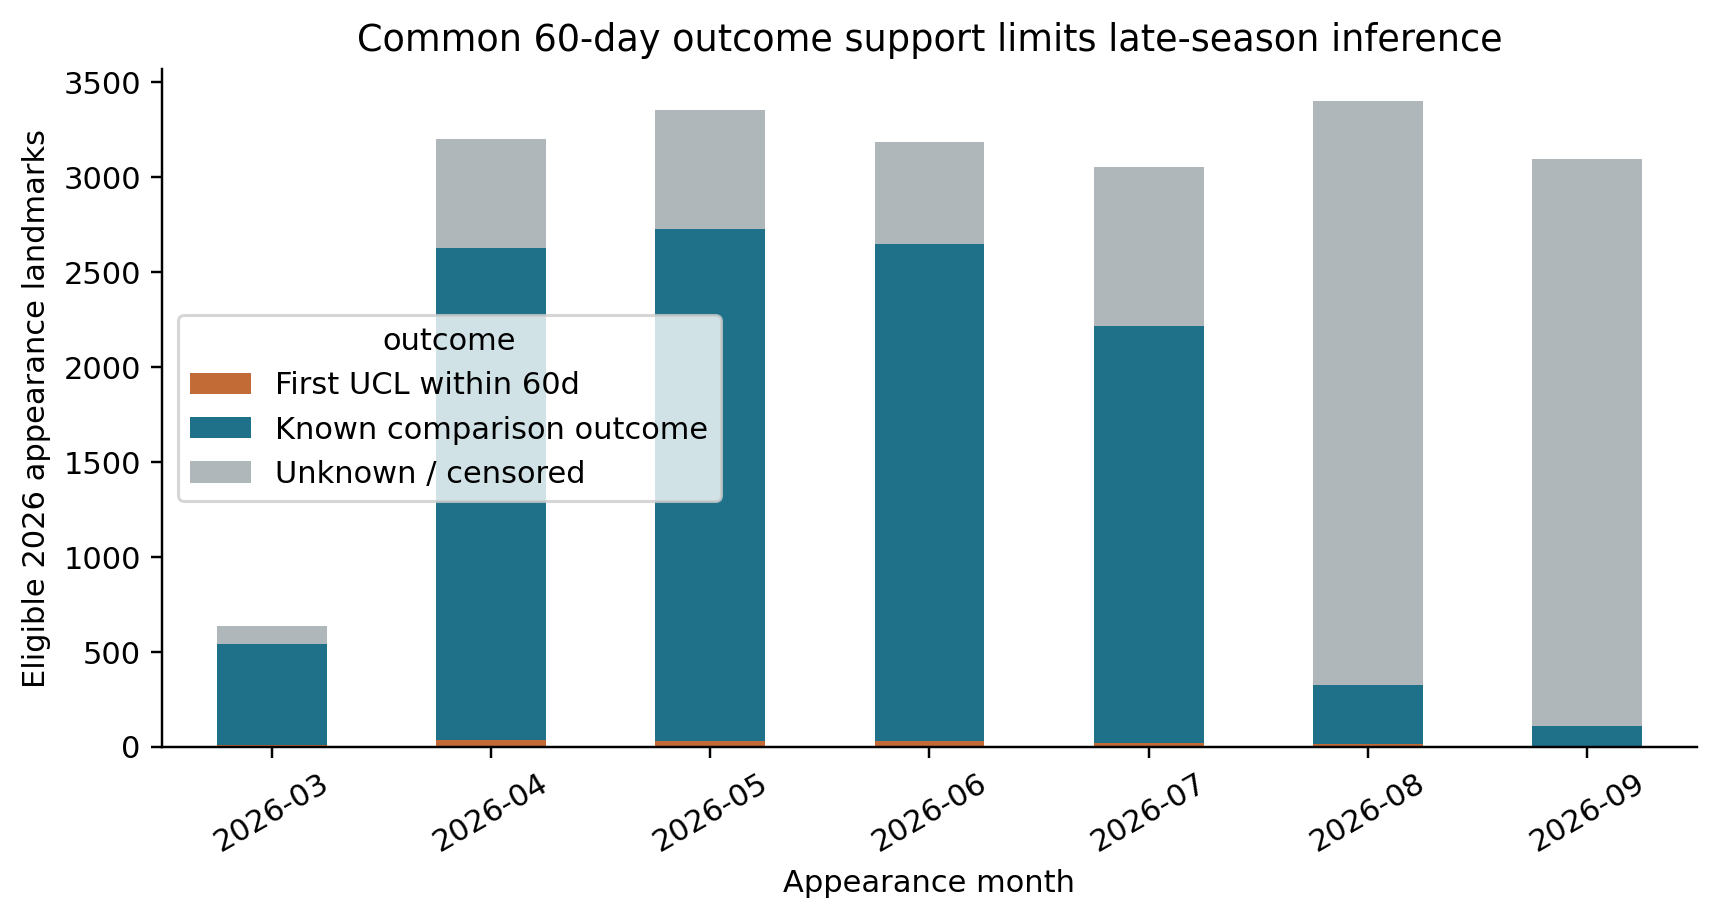

In [2]:
display(read('cohort_support'))
show('06_followup_support')

## Replication, shared events and uncertainty

Distinguish rank discrimination from the incremental near-minus-far ablation contrasts. Same-direction point estimates do not establish similar effect size or temporal mechanisms. Shared-event results change composition without refitting.

,interval,model,average_precision,prevalence,pr_lift,roc_auc,brier_score,calibration_bias,represented_events
0,1-7,Only | Pitcher background and experience,0.013284,0.002589,5.131874,0.701101,0.002576,-0.000613,16
1,1-7,Only | Velocity,0.005175,0.002589,1.999176,0.604405,0.002583,-0.000547,16
2,8-14,Only | Pitcher background and experience,0.004365,0.001607,2.716983,0.582323,0.001604,-0.000370,11
3,8-14,Only | Velocity,0.015392,0.001607,9.580104,0.723484,0.001601,-0.000241,11
4,15-30,Only | Pitcher background and experience,0.006744,0.003213,2.098839,0.649244,0.003201,-0.000984,12
5,15-30,Only | Velocity,0.004983,0.003213,1.550796,0.660413,0.003204,-0.000543,12
6,31-60,Only | Pitcher background and experience,0.007775,0.004909,1.583719,0.683930,0.004886,-0.002252,9
7,31-60,Only | Velocity,0.006249,0.004909,1.272846,0.608789,0.004900,-0.002127,9


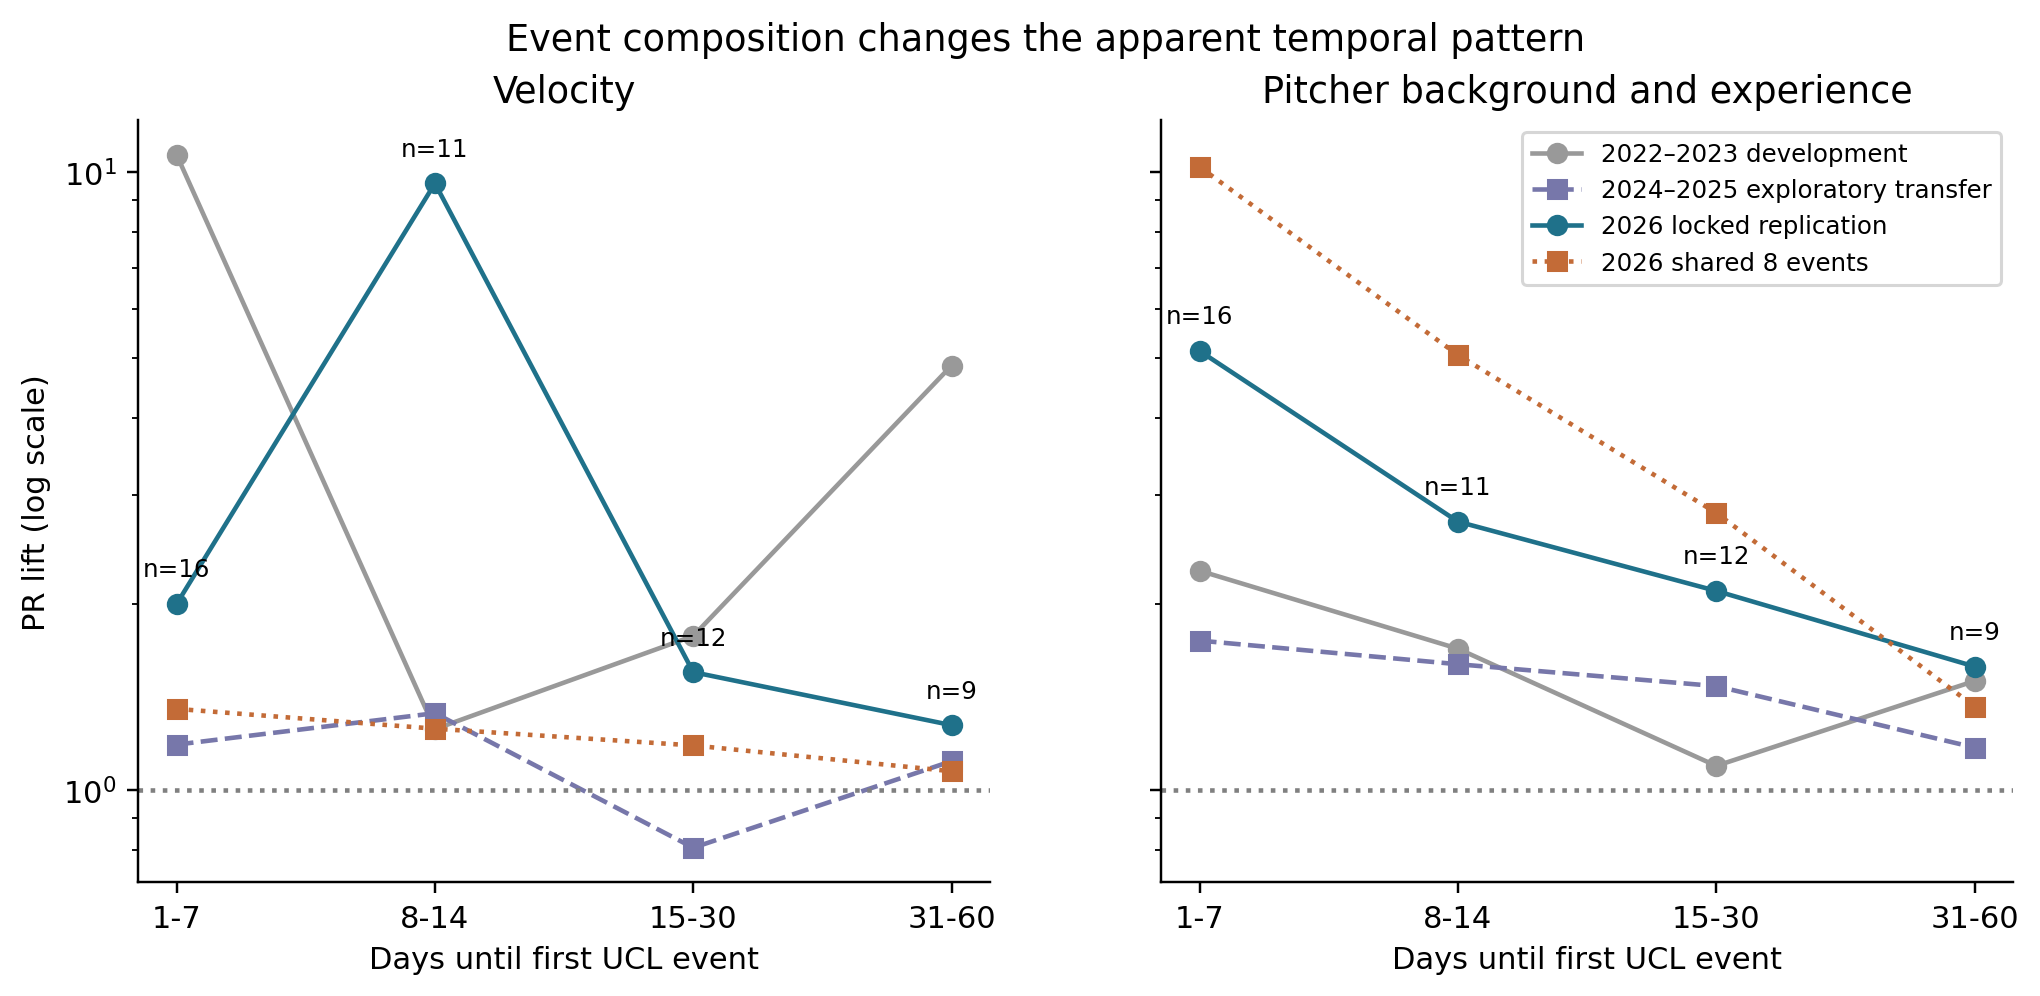

In [3]:
display(read('nominated_replication_metrics')[['interval','model','average_precision','prevalence','pr_lift','roc_auc','brier_score','calibration_bias','represented_events']])
show('01_replication_and_shared_events')

In [4]:
contrasts = read('temporal_contrasts')
display(contrasts.loc[contrasts.family.isin(spec['candidate_families'])])
print('Jointly supported original contrasts:', int(contrasts.simultaneously_supported.sum()), '/', len(contrasts))
display(read('reference_temporal_contrasts'))

,family,contrast,ablation_lift_difference,ci_low,ci_high,bootstrap_positive_fraction,valid_replicates,simultaneous_low,simultaneous_high,comparisons,simultaneous_critical_value,development_effect,transfer_effect,same_direction_development,same_direction_transfer,absolute_effect_difference,effect_ratio_to_development,simultaneously_supported
15,Pitcher background and experience,1-7 minus 31-60,-3.278279,-35.388233,3.513306,0.296667,300,-69.911974,63.355416,33,5.466278,-1.142920,2.996135,True,False,2.135360,2.868338,False
16,Pitcher background and experience,8-14 minus 31-60,2.629648,-1.045074,21.345862,0.910000,300,-31.837228,37.096523,33,5.466278,-1.410579,0.279542,False,True,4.040226,-1.864233,False
17,Pitcher background and experience,15-30 minus 31-60,0.637813,-0.897919,4.846028,0.800000,300,-10.415864,11.691490,33,5.466278,-2.293870,0.371554,False,True,2.931683,-0.278051,False
27,Velocity,1-7 minus 31-60,-7.684714,-42.356052,0.425108,0.046667,300,-90.580048,75.210619,33,5.466278,-0.480976,-0.618560,True,True,7.203739,15.977344,False
28,Velocity,8-14 minus 31-60,1.626371,-0.277518,17.077585,0.960000,300,-21.867751,25.120493,33,5.466278,-2.073832,-0.778082,False,False,3.700203,-0.784234,False
29,Velocity,15-30 minus 31-60,0.547752,-0.932747,14.186925,0.796667,300,-19.908984,21.004487,33,5.466278,-1.414445,-0.167975,False,False,1.962197,-0.387256,False


Jointly supported original contrasts: 0 / 33


,model,contrast,lift_difference,ci_low,ci_high,bootstrap_positive_fraction,valid_replicates
0,Departure,1-7 minus 31-60 PR lift,0.570825,-1.771168,2.775958,0.773333,300
1,Profile,1-7 minus 31-60 PR lift,0.602769,-0.206646,3.587860,0.913333,300
2,Background,1-7 minus 31-60 PR lift,3.548155,0.362950,19.930247,0.983333,300
3,Previous 62,1-7 minus 31-60 PR lift,13.565883,0.562001,80.693540,0.976667,300
4,Stable 62,1-7 minus 31-60 PR lift,3.342280,0.204919,11.409626,0.976667,300


## Event-level dependence is a primary result

Every primary estimate retains all events. AP contribution is an exact additive ranking decomposition. Leave-one-injured-pitcher-out removes that pitcher's positive and comparison rows from evaluation without refitting.

,interval,model,represented_events,injured_pitchers,original_ap,original_lift,largest_event_id,largest_event_ap_contribution,largest_event_fraction_ap,loo_ap_min,loo_ap_max,loo_lift_min,loo_lift_max,maximum_pitcher_ap_drop
0,1-7,Only | Pitcher background and experience,16,16,0.013284,5.131874,0db6b6fdaa2d8cff5f5f83850f21885b,0.003530,0.265755,0.007476,0.014286,3.099640,6.142594,0.005808
1,1-7,Only | Velocity,16,16,0.005175,1.999176,f65eeb0a7b6bbcf0a49c5bc76911f148,0.000886,0.171207,0.003583,0.005434,1.485893,2.336833,0.001592
2,8-14,Only | Pitcher background and experience,11,11,0.004365,2.716983,9244d4f7915565200d7ddb61214fb5e3,0.000907,0.207714,0.003109,0.005066,2.047434,4.049800,0.001256
3,8-14,Only | Velocity,11,11,0.015392,9.580104,9244d4f7915565200d7ddb61214fb5e3,0.011060,0.718512,0.003097,0.018112,2.167757,14.477628,0.012295
4,15-30,Only | Pitcher background and experience,12,12,0.006744,2.098839,26891c4513559a90126d19a7cfc88740,0.000835,0.123804,0.005090,0.007247,1.675714,2.793572,0.001655
5,15-30,Only | Velocity,12,12,0.004983,1.550796,26891c4513559a90126d19a7cfc88740,0.000985,0.197592,0.003301,0.005052,1.231291,1.719782,0.001683
6,31-60,Only | Pitcher background and experience,9,9,0.007775,1.583719,243c2617ad879fc80cec652c60d7ef37,0.001864,0.239777,0.005241,0.007960,1.363235,1.934767,0.002534
7,31-60,Only | Velocity,9,9,0.006249,1.272846,243c2617ad879fc80cec652c60d7ef37,0.001273,0.203753,0.004111,0.006353,1.069231,1.481648,0.002138


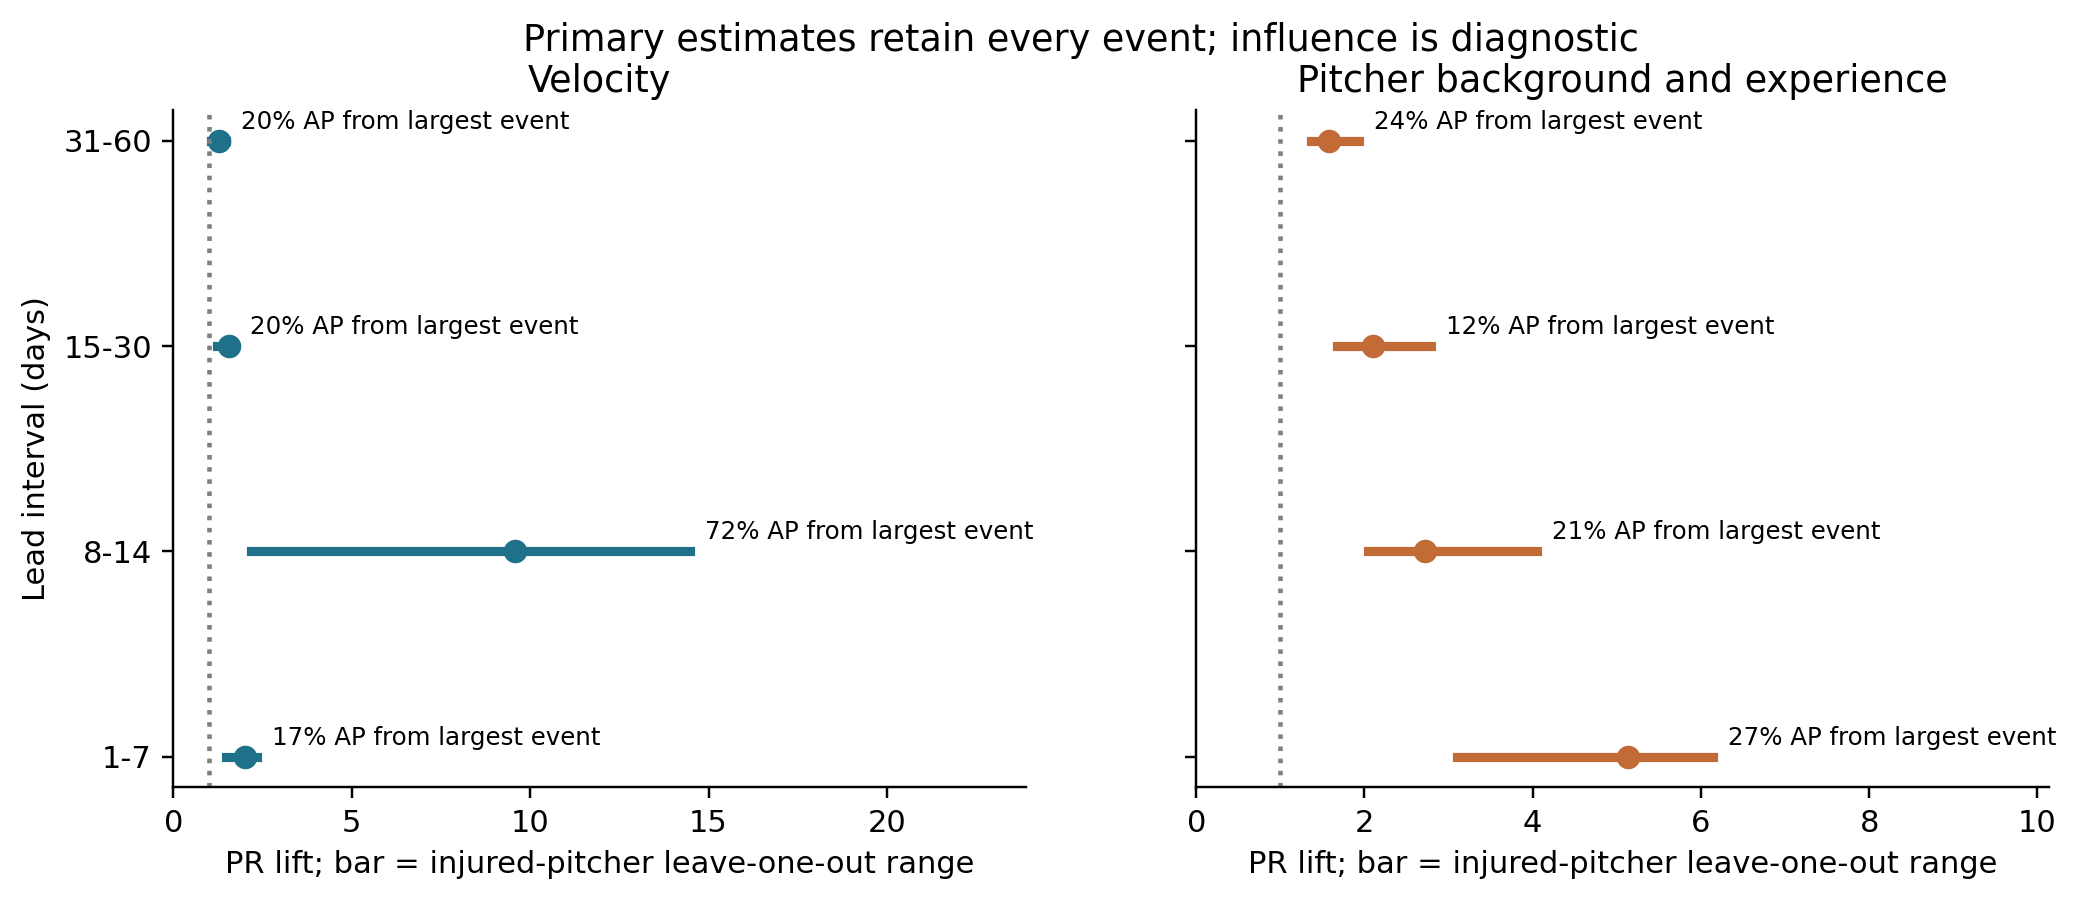

In [5]:
display(read('nominated_event_stability'))
show('02_event_dependence')

## Operational policies

Cutoffs come exclusively from original 2022–2023 development score quantiles. Consecutive alerts form episodes, broken by a non-alert, an ineligible outing, a season boundary, or a gap above 30 days. Actual 2026 rates can drift. Non-actionable fractions exclude unknown outcomes; unresolved alerts remain visible. Each interval/model is a separate policy.

,interval,model,detected_events,observable_events,realized_alert_rate,alert_episodes,alert_episodes_per_pitcher_season,alerts_per_detected_injury,non_actionable_alert_fraction,unknown_outcome_alerts,median_warning_lead_days
0,1-7,Only | Pitcher background and experience,5,16,0.172569,398,0.526455,688.000000,0.983573,2953,6.0
1,1-7,Only | Velocity,1,16,0.039681,402,0.531746,791.000000,0.995699,326,7.0
2,8-14,Only | Pitcher background and experience,2,11,0.134393,271,0.358466,1339.500000,0.995902,2191,12.5
3,8-14,Only | Velocity,2,11,0.052975,518,0.685185,528.000000,0.993056,480,13.5
4,15-30,Only | Pitcher background and experience,3,12,0.124110,251,0.332011,824.666667,0.989605,1993,25.0
5,15-30,Only | Velocity,1,12,0.052122,465,0.615079,1039.000000,0.995138,422,27.0
6,31-60,Only | Pitcher background and experience,1,9,0.073141,63,0.083333,1458.000000,0.995536,562,46.0
7,31-60,Only | Velocity,0,9,0.056637,346,0.457672,NaN,1.000000,454,NaN


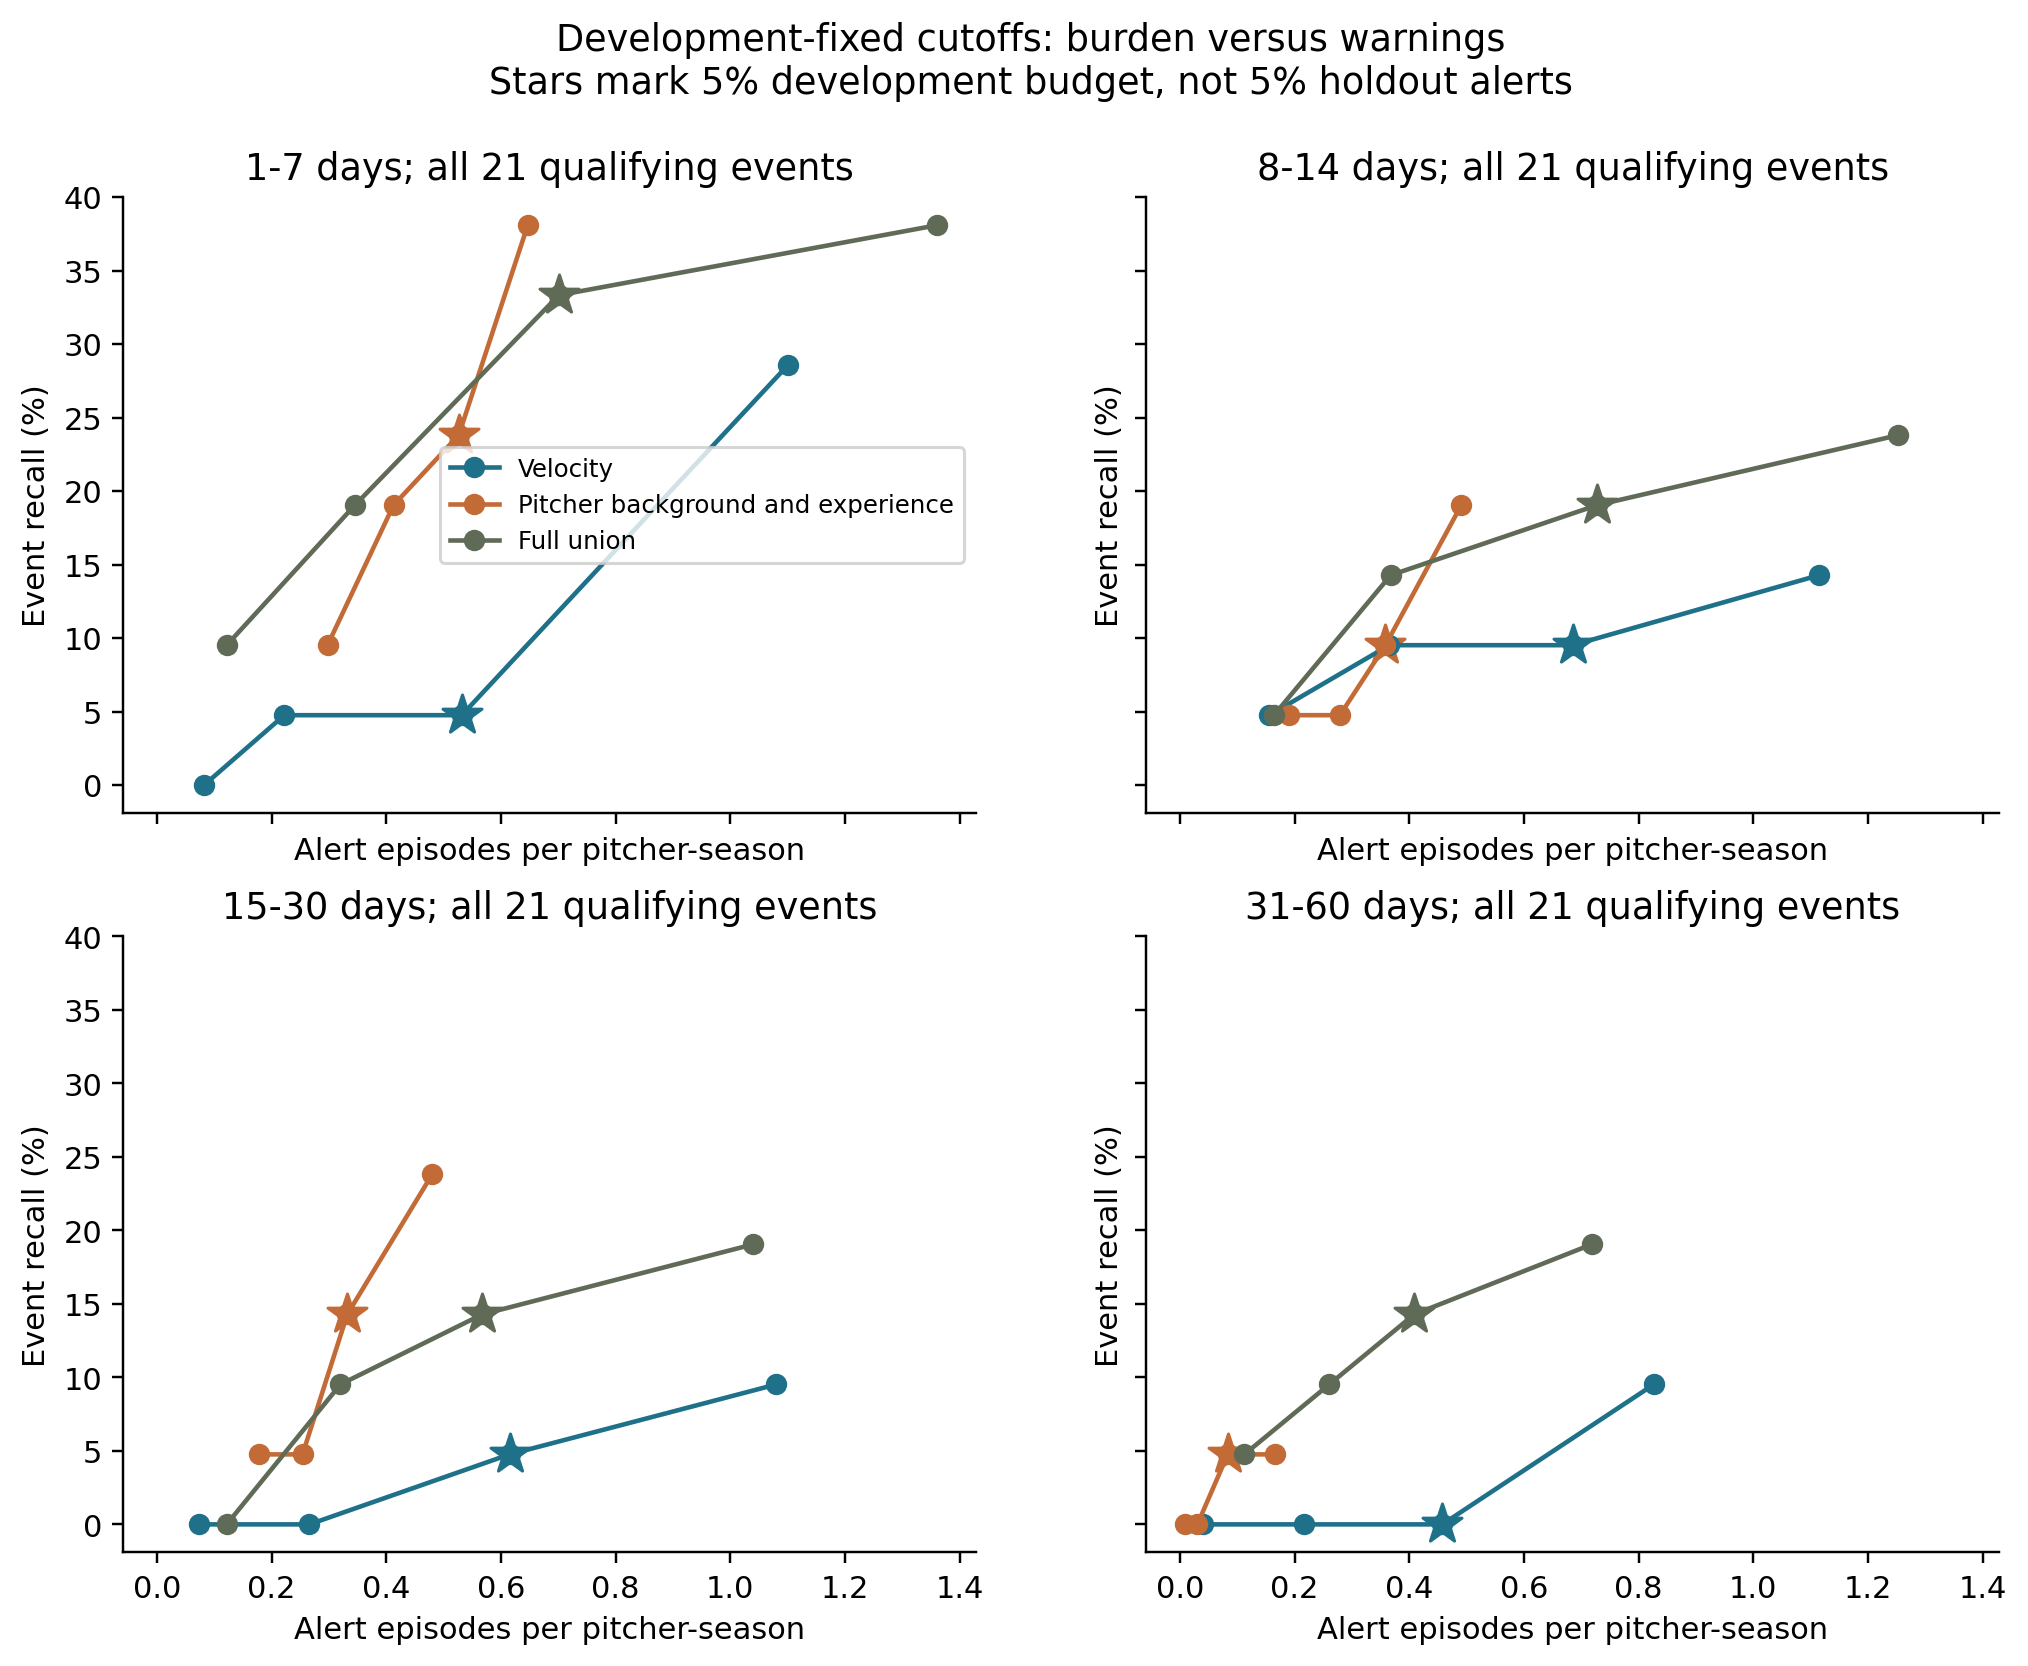

In [6]:
display(read('nominated_operational_policy')[['interval','model','detected_events','observable_events','realized_alert_rate','alert_episodes','alert_episodes_per_pitcher_season','alerts_per_detected_injury','non_actionable_alert_fraction','unknown_outcome_alerts','median_warning_lead_days']])
show('03_operational_warning_tradeoff')

## Calibration without recalibration

Bins are development-defined. The plot annotates full-union distinct-event counts per bin. Diagnostic intercept/slope fits require at least 10 represented events and 20 positive rows; they never change predictions.

,interval,model,positive_rows,represented_events,intercept,slope,intercept_se,slope_se,status
0,1-7,Full union,29,16,-2.807495,0.400777,1.457535,0.204321,diagnostic_only_no_recalibration
11,1-7,Only | Pitcher background and experience,29,16,1.665879,1.234693,2.742338,0.466515,diagnostic_only_no_recalibration
19,1-7,Only | Velocity,29,16,-3.245172,0.421883,2.048248,0.328588,diagnostic_only_no_recalibration
28,8-14,Full union,18,11,NaN,NaN,NaN,NaN,insufficient_event_support
39,8-14,Only | Pitcher background and experience,18,11,NaN,NaN,NaN,NaN,insufficient_event_support
47,8-14,Only | Velocity,18,11,NaN,NaN,NaN,NaN,insufficient_event_support
56,15-30,Full union,36,12,-3.148689,0.357006,1.299121,0.191447,diagnostic_only_no_recalibration
67,15-30,Only | Pitcher background and experience,36,12,0.406526,1.006637,3.012069,0.526293,diagnostic_only_no_recalibration
75,15-30,Only | Velocity,36,12,-1.187997,0.761095,1.812053,0.298591,diagnostic_only_no_recalibration
84,31-60,Full union,55,9,NaN,NaN,NaN,NaN,insufficient_event_support


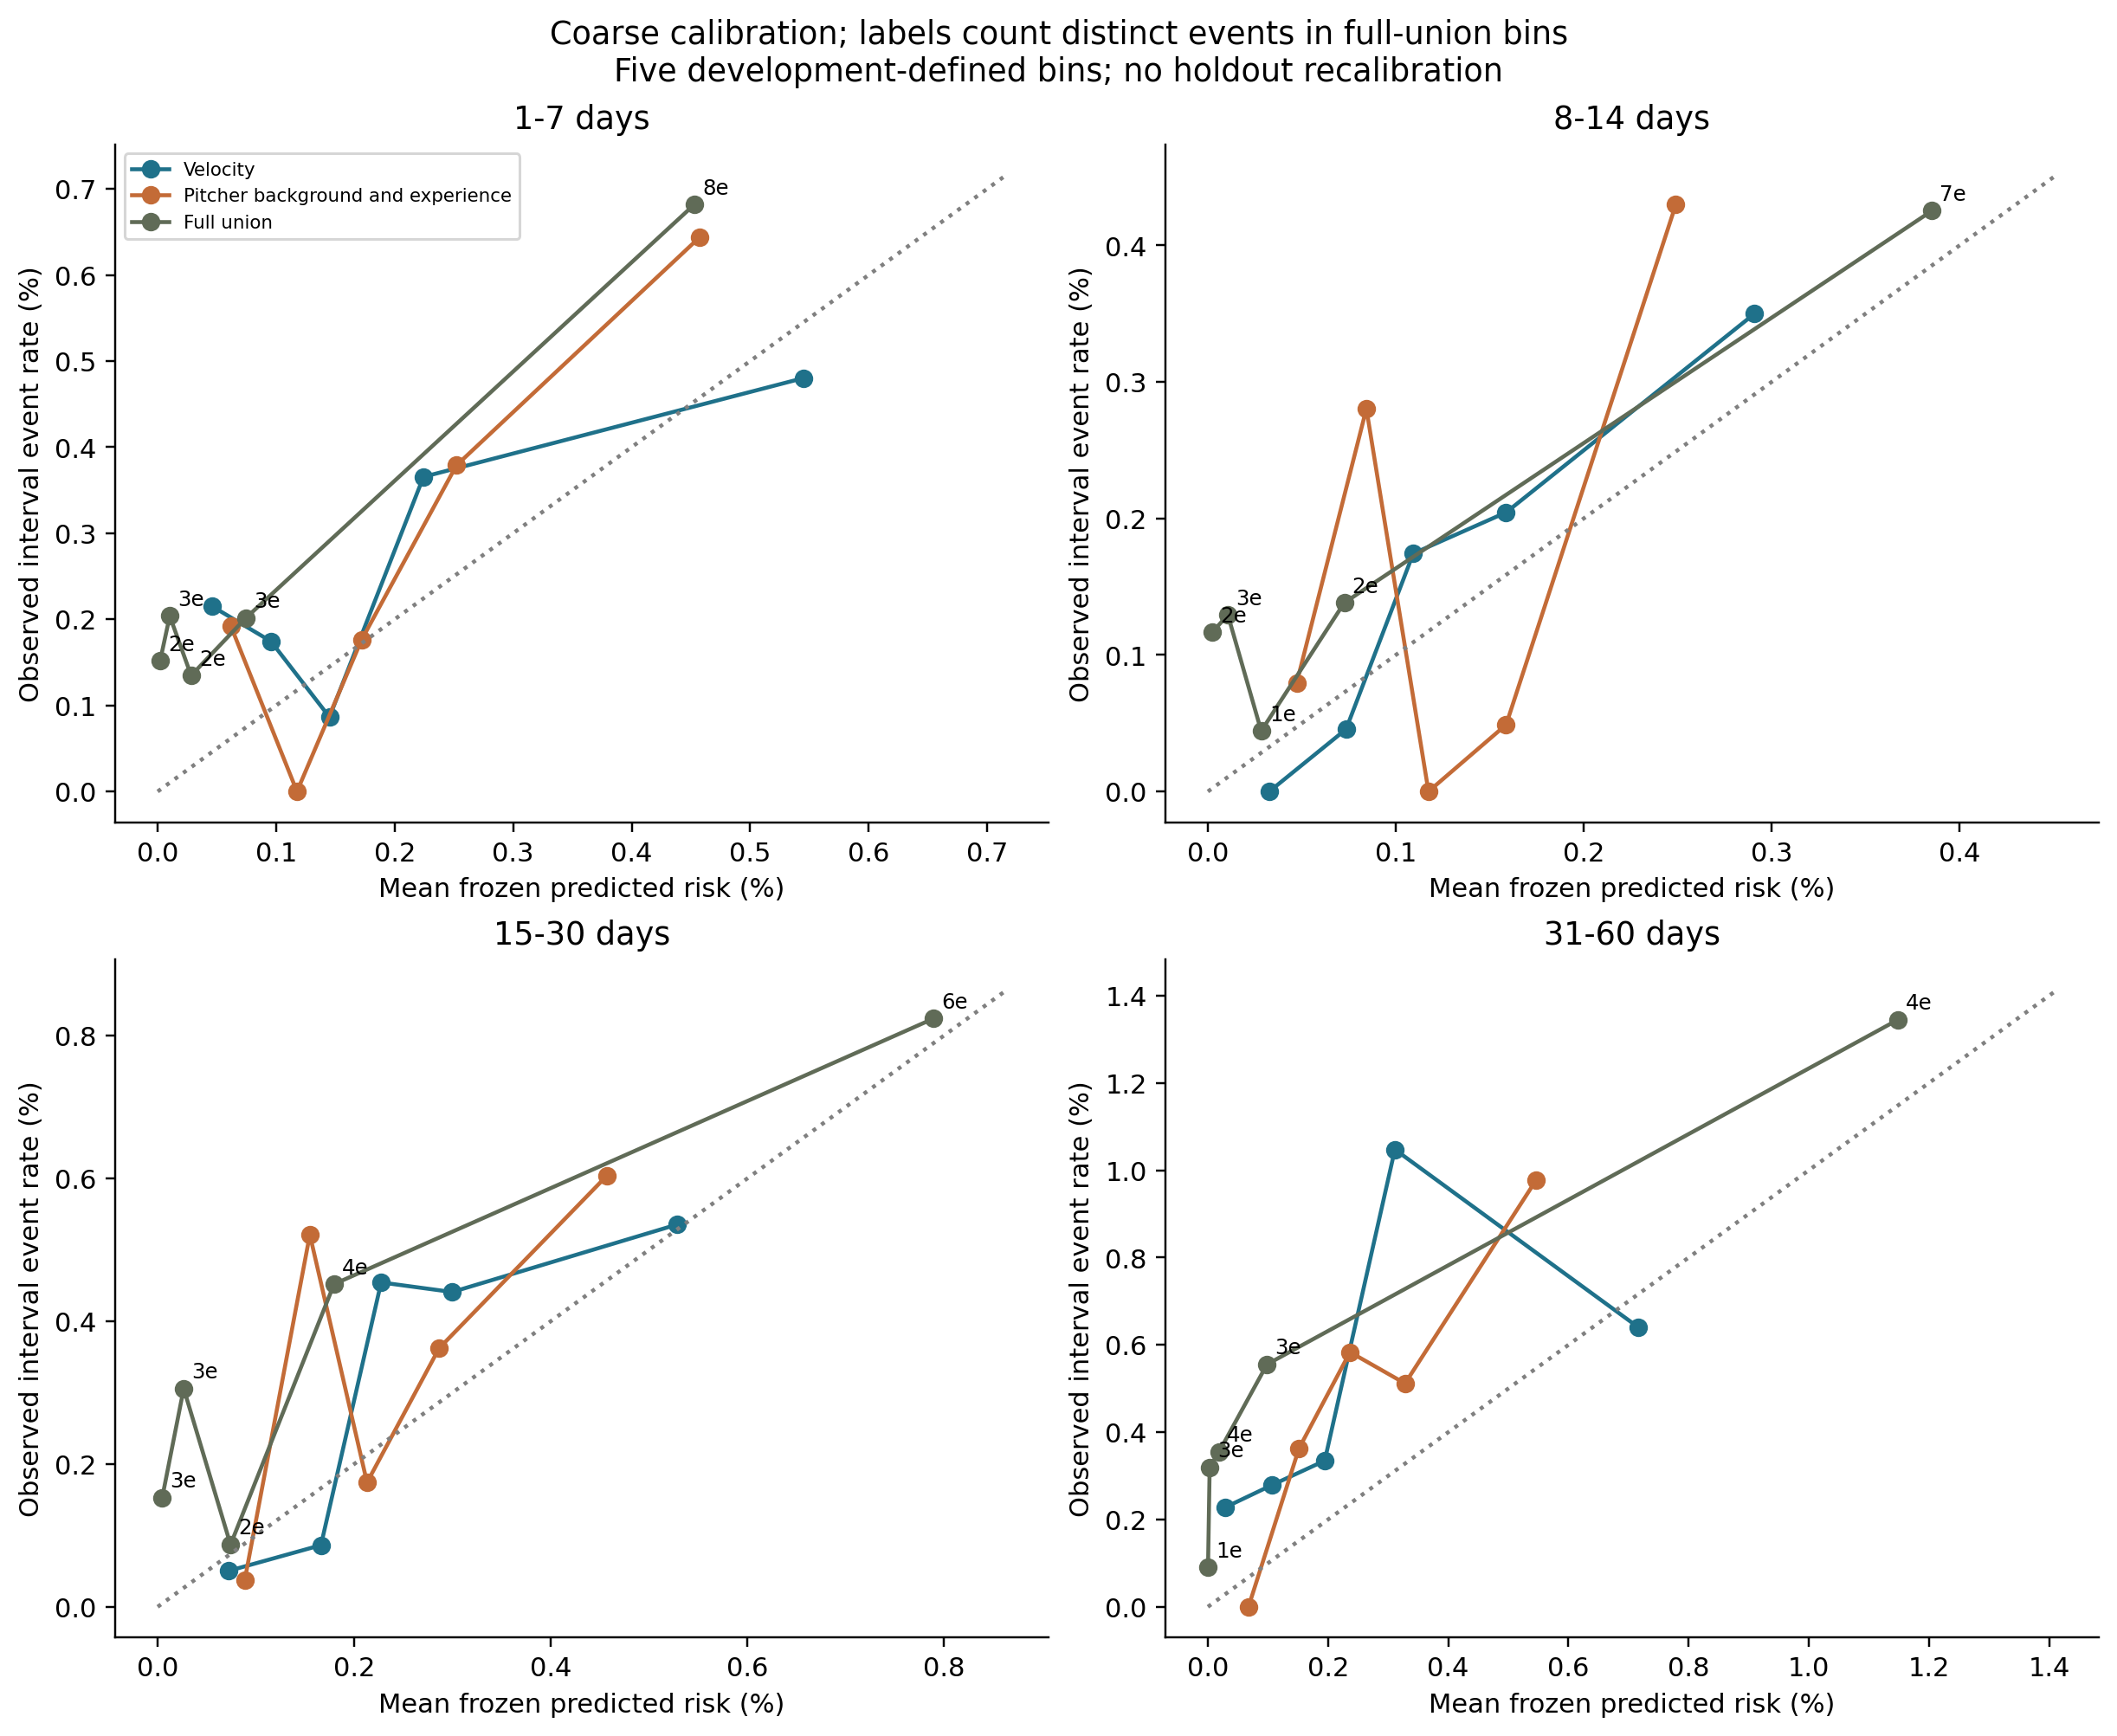

In [7]:
cal = read('calibration_diagnostics')
display(cal.loc[cal.model.isin(['Only | Velocity','Only | Pitcher background and experience','Full union'])])
show('04_calibration')

## Narrow workload/rest interpretation

The original matched sample is reused, with balanced case/control support and dependency-cluster intervals. These are earlier exploratory cohorts, not new 2026 matches. Pitch-count reduction can be observed; skipped scheduled starts, symptoms and clinical intent cannot be established from these measures.

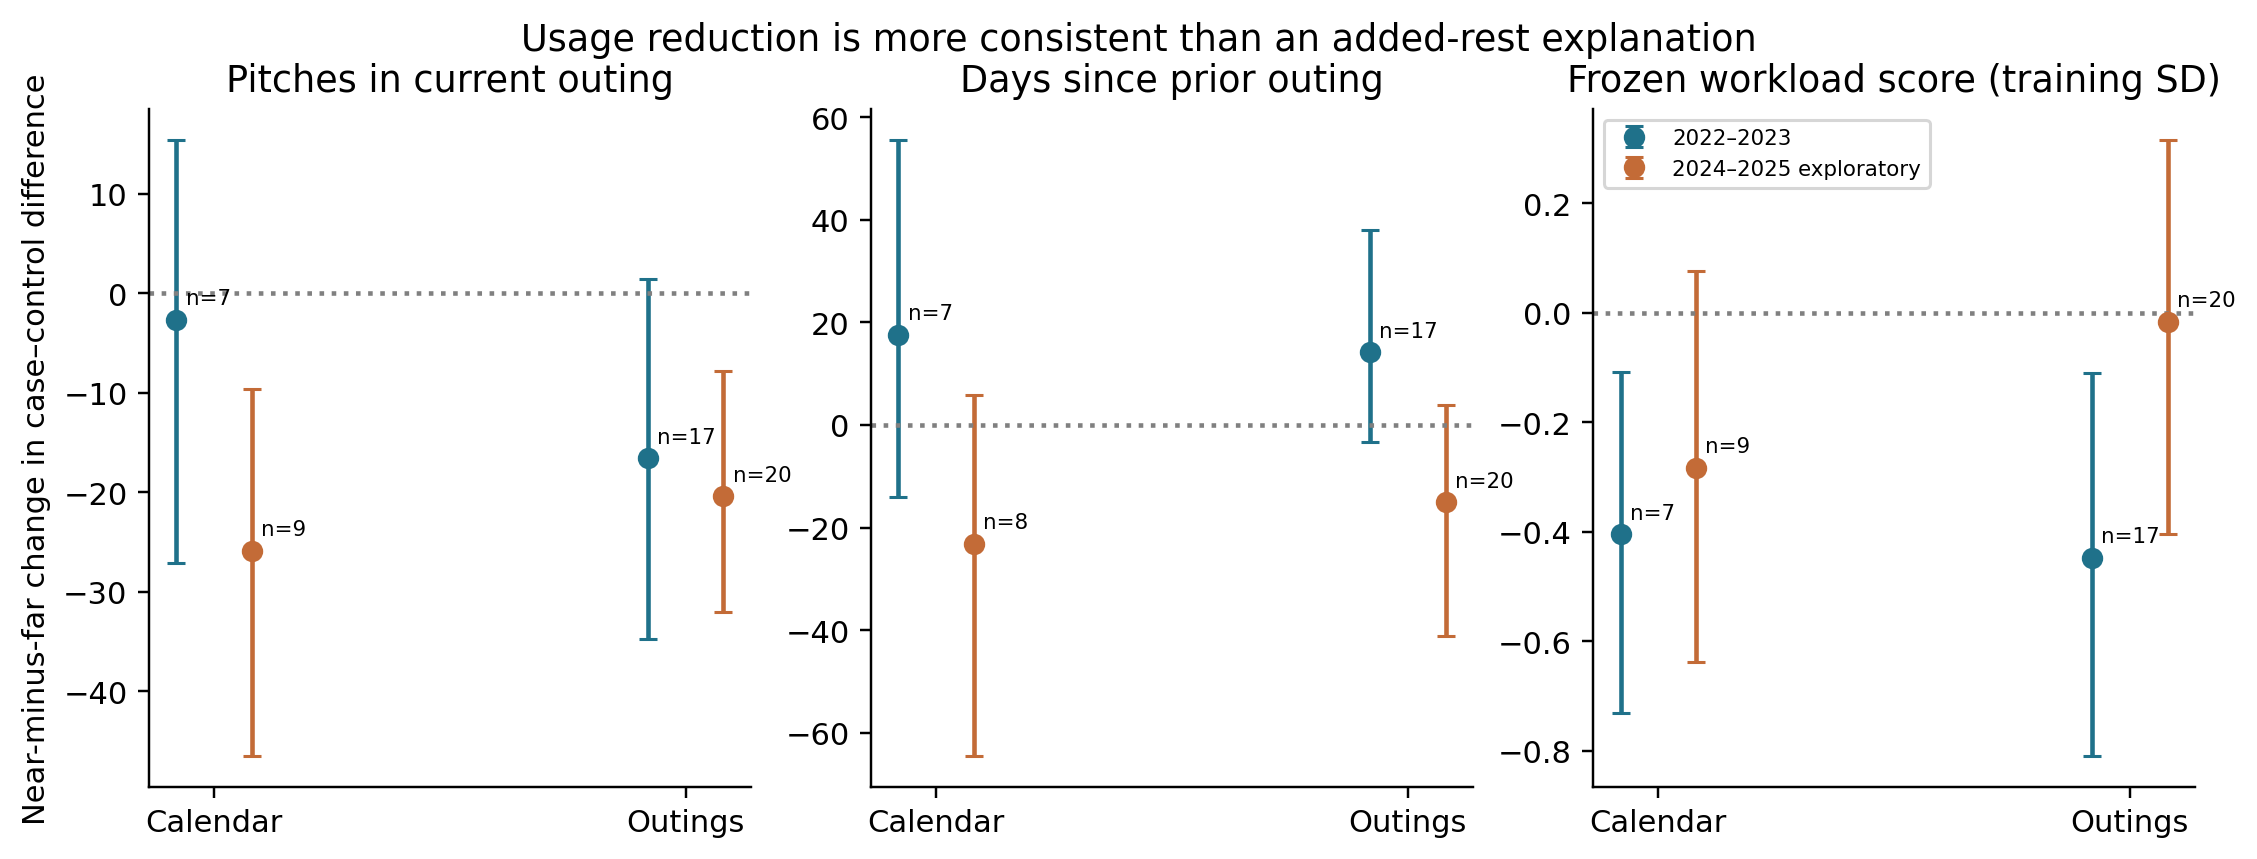

,partition,mode,field,kind,events,dependency_clusters,near_minus_far_case_control_difference,ci_low,ci_high,fraction_events_declining,magnitude
48,test,calendar,contribution__workload_acceleration_7d_vs_21d,coefficient_contribution,9,8,-0.750020,-1.535295,-0.029758,0.666667,0.750020
73,validation,outings,contribution__workload_acceleration_7d_vs_21d,coefficient_contribution,17,16,-0.668016,-1.377337,-0.024860,0.588235,0.668016
38,test,calendar,contribution__pitches_prev_7d,coefficient_contribution,9,8,0.588973,0.071123,1.132853,0.333333,0.588973
44,test,calendar,contribution__season_pitch_count,coefficient_contribution,9,8,-0.500649,-1.744953,0.441898,0.666667,0.500649
98,test,outings,contribution__workload_acceleration_7d_vs_21d,coefficient_contribution,20,19,-0.402068,-1.087802,0.456590,0.550000,0.402068
20,validation,calendar,contribution__season_innings,coefficient_contribution,7,7,0.395404,-0.025704,0.892662,0.428571,0.395404
99,test,outings,contribution__acute_chronic_pitch_ratio,coefficient_contribution,20,19,0.300437,0.131593,0.472436,0.300000,0.300437
94,test,outings,contribution__season_pitch_count,coefficient_contribution,20,19,-0.260236,-0.605724,0.016432,0.750000,0.260236
23,validation,calendar,contribution__workload_acceleration_7d_vs_21d,coefficient_contribution,7,7,-0.255074,-0.498087,-0.014620,0.714286,0.255074
63,validation,outings,contribution__pitches_prev_7d,coefficient_contribution,17,16,0.252894,-0.201792,0.709304,0.411765,0.252894


In [8]:
show('05_workload_interpretation')
w = read('workload_diagnostic')
display(w.loc[w.kind.eq('coefficient_contribution')].assign(magnitude=lambda x: x.near_minus_far_case_control_difference.abs()).sort_values('magnitude', ascending=False).groupby(['partition','mode']).head(3))

## Decision and limitations

Read the computed synthesis, including null contrasts, sparse-event limitations, unknown alerts, and the decision gate. Do not choose new models or thresholds from this notebook.

In [9]:
display(Markdown((OUT/'summary.md').read_text()))
display(read('validation_checks').groupby('passed').size().rename('checks'))

# Locked temporal replication and operational warning

**Decision: temporal heterogeneity remains unsupported. Continue toward dynamic multi-horizon UCL risk estimation; do not build an acute/intermediate/chronic architecture from these results.** Some discrimination survives, but timing specificity, event stability and useful warning burden are different questions. None of the 33 original family timing contrasts excludes zero under the original joint bootstrap procedure; 2/6 nominated-family contrasts have the same sign as development. Same direction alone does not demonstrate similar magnitude, statistical support or operational value.

## Locked design and support

The original `ucl_temporal` freeze, 28 fixed C=1 L2 logistic model definitions, 113-field union, 11 families and four intervals remain unchanged. Models and preprocessing were originally trained in 2015–2021; development validation was 2022–2023. The 2024–2025 results retain their exploratory-transfer interpretation. No model was fitted or selected in this replication. This specifically applies the original temporal freeze, while the separate revised-training study remains separate.

2026 is **locked retrospective chronological replication sensitivity**, not prospective or fully independent confirmation: these dates predate the October 20 development freeze and existed elsewhere in the project. The operational specification and cutoffs were frozen at 2026-10-22T03:02:19.643904+00:00 before replication scoring. Source observation ends 2026-10-20; regular-season appearances end 2026-09-27.

| interval | rows | pitchers | positive_rows | represented_events | qualifying_events | unknown_rows |
| --- | --- | --- | --- | --- | --- | --- |
| 1-7 | 11203 | 546 | 29 | 16 | 21 | 8731 |
| 8-14 | 11203 | 546 | 18 | 11 | 21 | 8731 |
| 15-30 | 11203 | 546 | 36 | 12 | 21 | 8731 |
| 31-60 | 11203 | 546 | 55 | 9 | 21 | 8731 |

The same **11,203 observed 60-day first-event rows** underlie all interval estimates. There are 19,934 eligible landmarks and 8,731 unknown/censored rows. A known competing injury ends the first-event interval; unknown/ambiguous episodes remain censored. UCL in another interval is an interval-specific negative, not a healthy-pitcher declaration. Late-season absence of observed follow-up never becomes a negative. The latest observed event-free 60-day landmark is 2026-07-29. With only 9–16 represented events per interval, this supports a limited sensitivity analysis, not precise confirmation of timing differences.

## Ranking and event dependence

| interval | model | average_precision | prevalence | pr_lift | roc_auc | brier_score | calibration_bias |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1-7 | Only / Pitcher background and experience | 0.0133 | 0.0026 | 5.1319 | 0.7011 | 0.0026 | -0.0006 |
| 1-7 | Only / Velocity | 0.0052 | 0.0026 | 1.9992 | 0.6044 | 0.0026 | -0.0005 |
| 8-14 | Only / Pitcher background and experience | 0.0044 | 0.0016 | 2.7170 | 0.5823 | 0.0016 | -0.0004 |
| 8-14 | Only / Velocity | 0.0154 | 0.0016 | 9.5801 | 0.7235 | 0.0016 | -0.0002 |
| 15-30 | Only / Pitcher background and experience | 0.0067 | 0.0032 | 2.0988 | 0.6492 | 0.0032 | -0.0010 |
| 15-30 | Only / Velocity | 0.0050 | 0.0032 | 1.5508 | 0.6604 | 0.0032 | -0.0005 |
| 31-60 | Only / Pitcher background and experience | 0.0078 | 0.0049 | 1.5837 | 0.6839 | 0.0049 | -0.0023 |
| 31-60 | Only / Velocity | 0.0062 | 0.0049 | 1.2728 | 0.6088 | 0.0049 | -0.0021 |

Velocity's strongest 2026 point estimate moves to 8–14 days, rather than reproducing the original 1–7-day peak. Its lift is 9.58, but **71.9% of AP comes from one event**. The lowest injured-pitcher leave-one-out lift is 2.17; all primary analyses retain that event. Exact AP contribution is an additive ranking decomposition, while leave-one-pitcher-out removes all that pitcher's evaluation rows; the two diagnostics have different meanings.

| interval | model | largest_event_fraction_ap | loo_lift_min | loo_lift_max |
| --- | --- | --- | --- | --- |
| 1-7 | Only / Pitcher background and experience | 0.2658 | 3.0996 | 6.1426 |
| 1-7 | Only / Velocity | 0.1712 | 1.4859 | 2.3368 |
| 8-14 | Only / Pitcher background and experience | 0.2077 | 2.0474 | 4.0498 |
| 8-14 | Only / Velocity | 0.7185 | 2.1678 | 14.4776 |
| 15-30 | Only / Pitcher background and experience | 0.1238 | 1.6757 | 2.7936 |
| 15-30 | Only / Velocity | 0.1976 | 1.2313 | 1.7198 |
| 31-60 | Only / Pitcher background and experience | 0.2398 | 1.3632 | 1.9348 |
| 31-60 | Only / Velocity | 0.2038 | 1.0692 | 1.4816 |

Background AP is less concentrated: the largest event accounts for roughly 12–27% across intervals, compared with the 72% velocity peak. This is relative ranking stability, not proof of a timing-specific mechanism.

Only **8 events** are represented in every interval. Keeping the original shared-event comparison rule lowers the 8–14-day velocity lift to **1.26**. Background retains a proximal ranking gradient in this restricted sample, but its incremental timing contrasts remain uncertain. Event-composition restriction is retrospective and not a new target population or fitting rule.

| interval | model | pr_lift_all | pr_lift_shared | shared_events |
| --- | --- | --- | --- | --- |
| 1-7 | Only / Pitcher background and experience | 5.1319 | 10.1871 | 8 |
| 1-7 | Only / Velocity | 1.9992 | 1.3524 | 8 |
| 8-14 | Only / Pitcher background and experience | 2.7170 | 5.0553 | 8 |
| 8-14 | Only / Velocity | 9.5801 | 1.2562 | 8 |
| 15-30 | Only / Pitcher background and experience | 2.0988 | 2.8070 | 8 |
| 15-30 | Only / Velocity | 1.5508 | 1.1803 | 8 |
| 31-60 | Only / Pitcher background and experience | 1.5837 | 1.3645 | 8 |
| 31-60 | Only / Velocity | 1.2728 | 1.0721 | 8 |

The exact 33 near-minus-31–60-day normalized ablation contrasts, original five reference contrasts, joint max-t bands, shared-event contrasts and continuous development-to-replication effect differences are saved. There was no prespecified equivalence margin; wide intervals and same-sign estimates cannot establish similar effect size. Bootstrap intervals resample whole pitchers and are conditional on frozen fits; they do not capture all model-development or injury-ascertainment uncertainty.

## Operational warnings

All 1%, 2.5%, 5% and 10% cutoffs are numeric score quantiles of the original **2022–2023 observed-outcome validation rows**. They are never optimized on 2026. Deployment applies them to **all eligible 2026 landmarks**, including unknown-outcome rows. Consecutive alerts form an episode within pitcher-season; any non-alert or ineligible outing, season boundary, or >30-day gap breaks it. Alert grouping uses no future outcome information. Each interval/model is evaluated separately; these are not combined into an ensemble warning system.

At the 5% development cutoff:

| interval | model | detected_events | observable_events | realized_alert_rate | alert_episodes | alert_episodes_per_pitcher_season | alerts_per_detected_injury | non_actionable_alert_fraction | unknown_outcome_alerts | median_warning_lead_days |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1-7 | Only / Pitcher background and experience | 5 | 16 | 0.1726 | 398 | 0.5265 | 688.0000 | 0.9836 | 2953 | 6.0000 |
| 1-7 | Only / Velocity | 1 | 16 | 0.0397 | 402 | 0.5317 | 791.0000 | 0.9957 | 326 | 7.0000 |
| 8-14 | Only / Pitcher background and experience | 2 | 11 | 0.1344 | 271 | 0.3585 | 1339.5000 | 0.9959 | 2191 | 12.5000 |
| 8-14 | Only / Velocity | 2 | 11 | 0.0530 | 518 | 0.6852 | 528.0000 | 0.9931 | 480 | 13.5000 |
| 15-30 | Only / Pitcher background and experience | 3 | 12 | 0.1241 | 251 | 0.3320 | 824.6667 | 0.9896 | 1993 | 25.0000 |
| 15-30 | Only / Velocity | 1 | 12 | 0.0521 | 465 | 0.6151 | 1039.0000 | 0.9951 | 422 | 27.0000 |
| 31-60 | Only / Pitcher background and experience | 1 | 9 | 0.0731 | 63 | 0.0833 | 1458.0000 | 0.9955 | 562 | 46.0000 |
| 31-60 | Only / Velocity | 0 | 9 | 0.0566 | 346 | 0.4577 | — | 1.0000 | 454 | — |

All-event recall uses **21 qualifying events**, including those without eligible opportunities; observable-event recall uses the interval's supported subset. The nominated models detect only **0–5 events per interval**, despite hundreds of alert episodes. Among alerts with known outcomes, roughly **98–100% are not followed by the target interval UCL event**. This is not proof that those pitchers were healthy or that alerts lacked every possible clinical use. Unknown alerts are explicitly unresolved, not false. Background cutoffs produce about **7–17%** actual alert rates across intervals despite the 5% development budget, with long persistent alert episodes. The source of this operational drift is not resolved by ranking AP. Realized rates and unresolved-alert fractions should be monitored before deployment.

The 1–7-day endpoint remains proximal and does not establish useful ≥7-day warning. Longer-window detections provide median leads shown above, but often involve only one or two events. Detection fractions and earliest/median lead times must be read with their event counts. No cutoff is endorsed for clinical action from these data. The original retrospective top-5% warning calculation is retained as context, clearly separated from fixed-threshold operational results.

## Calibration and workload interpretation

Most headline models underpredict the observed interval prevalence. Brier score and mean-risk bias are reported for every interval; coarse reliability bins use development-defined edges and show distinct event counts. Diagnostic intercept/slope fits were allowed only with at least 10 represented events and 20 positive rows: 1–7 and 15–30 days qualify; 8–14 and 31–60 remain too sparse by that locked rule. No diagnostic fit recalibrates any predictions.

The workload diagnostic reuses the original matched pairs and one fixed training-derived workload score. The original development score decreases are exactly reproduced. In 2024–2025 exploratory transfer, the calendar score change is −0.283 training SD (interval crosses zero), and the outing change is −0.016 SD. Current pitch counts decrease relative to controls by about 26 pitches in calendar alignment and 20 pitches in outing alignment; added rest does **not** replicate consistently. Workload acceleration, recent pitch volume and season workload have offsetting signed contributions. This supports usage reduction as an interpretation to investigate, not a causal injury mechanism or evidence of skipped scheduled starts. Symptoms, intent and missed starts are not established by the available data. Raw support, dependency-cluster intervals, event changes and leave-event-out means are retained. Removing any one event leaves the development workload-score change negative in both alignments; the exploratory-transfer outing change ranges from −0.074 to +0.139 SD when individual events are omitted, so even its direction is unstable.

## What to carry forward

Keep the nominated families and fixed interval definitions for future replication, but simplify the scientific framing to **dynamic multi-horizon UCL risk estimation**. Do not force distinct acute/intermediate/chronic mechanisms. Mature late-2026 outcomes in a separately versioned evaluation using these same frozen models and cutoffs; any later policy redesign must use a development cohort, not these holdout results. A future heterogeneous architecture requires more stable event-level and shared-event evidence plus a defensible operational burden.

## Reproduction and artifacts

- Methods: `docs/ucl_temporal_replication_methods.md`.
- Frozen configuration: `config/ucl_temporal_replication.yaml`; operational/model hashes: `replication_freeze.json`.
- Reusable entry point: `.venv/bin/python -m src.injury_analysis.ucl_replication_pipeline`.
- Synthesis: `notebooks/ucl_temporal_replication/01_locked_replication.ipynb`.
- Tables cover support/censoring, all 112 model-interval metrics, original contrasts, event influence, shared-event sensitivity, 448 fixed-threshold policies, episode/event warning details, calibration and matched workload diagnostics.
- Six figures, each PNG/PDF, are in `figures/`.
- **472 analysis checks passed**, **392 original temporal artifacts verified unchanged**, **zero model refits**. Unit-test and notebook execution logs are saved beside this summary.


passed
True    472
Name: checks, dtype: int64